# Experiment: FLUX.2 VAE Palette Evaluation on Public ARC Development Tasks

This Colab experiment asks whether the standard ARC colors, an RGB-maximin
palette, or a FLUX.2-VAE-latent-maximin palette is the most robust target
representation for real ARC output grids.

The public labelled ARC `evaluation` split is treated as a **development
set**, not as an untouched final benchmark. The hidden Kaggle private set
remains the final system-level evaluation.

Success criteria:

- load and fingerprint the expected 120-task / 167-output local data version;
- compare all three palettes on every output and a deterministic augmented copy;
- extend normalized latent noise until the clean-roundtrip ceiling breaks;
- measure strict grid, inferred shape, true-grid cell, and PAD performance;
- save enough configuration and output artifacts to reproduce the decision.

## Colab prerequisites

Select an A100 runtime and keep the following files in Google Drive:

```text
MyDrive/diffusion-arc/
├── models/flux2-klein-base-4b/vae/
│   ├── config.json
│   └── diffusion_pytorch_model.safetensors
└── data/raw/arc-agi-2/evaluation/
    └── <one JSON file per task>
```

The dataset is already available locally in the repository. Copy that
`evaluation` directory to Drive once before running this notebook.

In [ ]:
from __future__ import annotations

import importlib.metadata
import subprocess
import sys

PINNED_PACKAGES = {
    'diffusers': '0.39.0',
    'transformers': '4.56.1',
    'accelerate': '1.12.0',
    'safetensors': '0.8.0',
    'Pillow': '11.3.0',
}

requirements = []
for distribution, expected_version in PINNED_PACKAGES.items():
    try:
        installed_version = importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError:
        installed_version = None
    if installed_version != expected_version:
        requirements.append(f'{distribution}=={expected_version}')

if requirements:
    print('Installing:', ' '.join(requirements))
    subprocess.run(
        [
            sys.executable,
            '-m',
            'pip',
            'install',
            '--quiet',
            '--no-cache-dir',
            '--upgrade-strategy',
            'only-if-needed',
            *requirements,
        ],
        check=True,
    )
else:
    print('All pinned experiment packages already match.')

{name: importlib.metadata.version(name) for name in PINNED_PACKAGES}

Installing: transformers==4.56.1 accelerate==1.12.0


{'diffusers': '0.39.0',
 'transformers': '4.56.1',
 'accelerate': '1.12.0',
 'safetensors': '0.8.0',
 'Pillow': '11.3.0'}

## Runtime, checkpoint, and data paths

The VAE weight hash prevents a silent checkpoint change. Model loading is
offline after the Drive mount; the only optional copy is from Drive to the
Colab VM's local SSD.

In [ ]:
import hashlib
import os
import shutil
from pathlib import Path

import numpy as np
import torch
from google.colab import drive

DRIVE_MOUNT = Path('/content/drive')
DRIVE_ROOT = DRIVE_MOUNT / 'MyDrive' / 'diffusion-arc'
MODEL_PATH = DRIVE_ROOT / 'models' / 'flux2-klein-base-4b'
VAE_SOURCE_PATH = MODEL_PATH / 'vae'
EVALUATION_DATA_DIR = DRIVE_ROOT / 'data' / 'raw' / 'arc-agi-2' / 'evaluation'
LOCAL_VAE_PATH = Path('/content/flux2-klein-base-4b-vae')
OUTPUT_DIR = DRIVE_ROOT / 'outputs' / 'vae-palette-real-evaluation'
EXPECTED_VAE_SHA256 = 'ca70d2202afe6415bdbcb8793ba8cd99fd159cfe6192381504d6c4d3036e0f04'
GPU_INDEX = 0
COPY_VAE_TO_LOCAL_SSD = True

drive.mount(str(DRIVE_MOUNT), force_remount=False)
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'

assert torch.cuda.is_available(), 'Select Runtime > Change runtime type > GPU.'
assert GPU_INDEX < torch.cuda.device_count()
torch.cuda.set_device(GPU_INDEX)
DEVICE = torch.device(f'cuda:{GPU_INDEX}')

required_files = ('config.json', 'diffusion_pytorch_model.safetensors')
missing_source = [name for name in required_files if not (VAE_SOURCE_PATH / name).is_file()]
assert not missing_source, f'Incomplete Drive VAE directory: {missing_source}'
assert EVALUATION_DATA_DIR.is_dir(), (
    'Copy data/raw/arc-agi-2/evaluation to '
    f'{EVALUATION_DATA_DIR} before running the experiment.'
)

if COPY_VAE_TO_LOCAL_SSD:
    if not LOCAL_VAE_PATH.exists():
        shutil.copytree(VAE_SOURCE_PATH, LOCAL_VAE_PATH)
    missing_local = [name for name in required_files if not (LOCAL_VAE_PATH / name).is_file()]
    assert not missing_local, f'Incomplete local VAE copy: {missing_local}'
    VAE_PATH = LOCAL_VAE_PATH
else:
    VAE_PATH = VAE_SOURCE_PATH

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

vae_weight_path = VAE_PATH / 'diffusion_pytorch_model.safetensors'
vae_sha256 = sha256_file(vae_weight_path)
assert vae_sha256 == EXPECTED_VAE_SHA256, (EXPECTED_VAE_SHA256, vae_sha256)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

gpu = torch.cuda.get_device_properties(GPU_INDEX)
runtime = {
    'gpu': gpu.name,
    'gpu_memory_GiB': round(gpu.total_memory / 2**30, 1),
    'torch': torch.__version__,
    'vae_path': str(VAE_PATH),
    'vae_sha256': vae_sha256,
    'evaluation_data_dir': str(EVALUATION_DATA_DIR),
    'output_dir': str(OUTPUT_DIR),
}
runtime

Mounted at /content/drive


{'gpu': 'NVIDIA A100-SXM4-40GB',
 'gpu_memory_GiB': 39.5,
 'torch': '2.11.0+cu128',
 'vae_path': '/content/flux2-klein-base-4b-vae',
 'vae_sha256': 'ca70d2202afe6415bdbcb8793ba8cd99fd159cfe6192381504d6c4d3036e0f04',
 'evaluation_data_dir': '/content/drive/MyDrive/diffusion-arc/data/raw/arc-agi-2/evaluation',
 'output_dir': '/content/drive/MyDrive/diffusion-arc/outputs/vae-palette-real-evaluation'}

## Fixed experiment configuration

Each source output contributes two views: the original and one deterministic
augmentation. Augmented geometries rotate through the same eight-element order
used by `ArcGeometry`; each augmented view receives an independently seeded
complete permutation of color IDs 0–9.

Three independent noise samples are evaluated at every non-zero sigma. Noise
is added to the normalized, packed transformer latent rather than the raw VAE
latent.

In [ ]:
SEED = 20260813
EXPECTED_TASK_COUNT = 120
EXPECTED_OUTPUT_COUNT = 167
GRID_SIZE = 30
CELL_SIZE = 16
IMAGE_SIZE = GRID_SIZE * CELL_SIZE
PAD_CLASS = 10
PAD_RGB = (255, 255, 255)
CANDIDATE_LEVELS = (0, 85, 170, 255)
SEARCH_CONTEXT_MOSAICS = 4
EVALUATION_CONTEXT_MOSAICS = 4
NOISE_SIGMAS = (0.0, 0.35, 0.50, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0)
NOISE_REPEATS = 3
BATCH_SIZE = 8
GEOMETRIES = ('ID', 'R90', 'R180', 'R270', 'FH', 'FV', 'FD1', 'FD2')

STANDARD_ARC_PALETTE = np.asarray(
    [
        (0x00, 0x00, 0x00),
        (0x00, 0x74, 0xD9),
        (0xFF, 0x41, 0x36),
        (0x2E, 0xCC, 0x40),
        (0xFF, 0xDC, 0x00),
        (0xAA, 0xAA, 0xAA),
        (0xF0, 0x12, 0xBE),
        (0xFF, 0x85, 0x1B),
        (0x7F, 0xDB, 0xFF),
        (0x87, 0x0C, 0x25),
        PAD_RGB,
    ],
    dtype=np.uint8,
)

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
assert len(GEOMETRIES) == 8
assert STANDARD_ARC_PALETTE.shape == (11, 3)
assert tuple(STANDARD_ARC_PALETTE[PAD_CLASS]) == PAD_RGB

{
    'seed': SEED,
    'expected_tasks': EXPECTED_TASK_COUNT,
    'expected_outputs': EXPECTED_OUTPUT_COUNT,
    'views_per_output': 2,
    'noise_sigmas': NOISE_SIGMAS,
    'noise_repeats': NOISE_REPEATS,
    'batch_size': BATCH_SIZE,
}

{'seed': 20260813,
 'expected_tasks': 120,
 'expected_outputs': 167,
 'views_per_output': 2,
 'noise_sigmas': (0.0, 0.35, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0),
 'noise_repeats': 3,
 'batch_size': 8}

## Load and freeze the FLUX.2 VAE

In [ ]:
from diffusers import AutoencoderKLFlux2

vae = AutoencoderKLFlux2.from_pretrained(
    VAE_PATH,
    torch_dtype=torch.float32,
    local_files_only=True,
    low_cpu_mem_usage=False,
)
vae.eval()
vae.requires_grad_(False)
vae.to(DEVICE)

assert not vae.training
assert not any(parameter.requires_grad for parameter in vae.parameters())
assert next(vae.parameters()).dtype == torch.float32
assert vae.config.latent_channels == 32

{
    'class': type(vae).__name__,
    'parameters': sum(parameter.numel() for parameter in vae.parameters()),
    'dtype': str(next(vae.parameters()).dtype),
    'frozen': not any(parameter.requires_grad for parameter in vae.parameters()),
}

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


{'class': 'AutoencoderKLFlux2',
 'parameters': 84046115,
 'dtype': 'torch.float32',
 'frozen': True}

## Load, validate, and fingerprint public development outputs

Only labelled query outputs are used: these are the images the diffusion model
must eventually generate. The demonstrations and query inputs are irrelevant to
this isolated VAE representation experiment.

In [ ]:
import json
from collections import Counter
from dataclasses import dataclass

@dataclass(frozen=True)
class ArcOutput:
    task_id: str
    query_index: int
    grid: np.ndarray

def validate_grid(grid: object, *, name: str) -> np.ndarray:
    array = np.asarray(grid)
    assert array.ndim == 2, f'{name} must be two-dimensional'
    assert 1 <= array.shape[0] <= GRID_SIZE, f'{name} height: {array.shape}'
    assert 1 <= array.shape[1] <= GRID_SIZE, f'{name} width: {array.shape}'
    assert np.issubdtype(array.dtype, np.integer), f'{name} must contain integers'
    array = array.astype(np.int64, copy=True)
    assert int(array.min()) >= 0 and int(array.max()) <= 9, f'{name} colors'
    array.setflags(write=False)
    return array

def load_evaluation_outputs(root: Path) -> tuple[list[ArcOutput], dict[str, object]]:
    paths = sorted(root.glob('*.json'))
    digest = hashlib.sha256()
    outputs = []
    outputs_per_task = Counter()
    color_counts = Counter()
    shapes = []

    for path in paths:
        raw = path.read_bytes()
        digest.update(path.name.encode('utf-8'))
        digest.update(b'\0')
        digest.update(raw)
        payload = json.loads(raw)
        assert isinstance(payload.get('train'), list), path.name
        assert isinstance(payload.get('test'), list), path.name
        assert payload['test'], f'{path.name} has no queries'

        for query_index, query in enumerate(payload['test']):
            assert 'input' in query and 'output' in query, (path.name, query_index)
            grid = validate_grid(
                query['output'],
                name=f'{path.stem}.test[{query_index}].output',
            )
            outputs.append(ArcOutput(path.stem, query_index, grid))
            outputs_per_task[path.stem] += 1
            color_counts.update(int(value) for value in grid.ravel())
            shapes.append(tuple(int(value) for value in grid.shape))

    stats = {
        'task_count': len(paths),
        'output_count': len(outputs),
        'outputs_per_task_histogram': dict(sorted(Counter(outputs_per_task.values()).items())),
        'height_range': [min(h for h, _ in shapes), max(h for h, _ in shapes)],
        'width_range': [min(w for _, w in shapes), max(w for _, w in shapes)],
        'area_range': [min(h * w for h, w in shapes), max(h * w for h, w in shapes)],
        'color_counts': dict(sorted(color_counts.items())),
        'sha256': digest.hexdigest(),
        'task_ids': [path.stem for path in paths],
    }
    return outputs, stats

SOURCE_OUTPUTS, dataset_stats = load_evaluation_outputs(EVALUATION_DATA_DIR)
assert dataset_stats['task_count'] == EXPECTED_TASK_COUNT, dataset_stats
assert dataset_stats['output_count'] == EXPECTED_OUTPUT_COUNT, dataset_stats

dataset_stats

{'task_count': 120,
 'output_count': 167,
 'outputs_per_task_histogram': {1: 75, 2: 43, 3: 2},
 'height_range': [2, 30],
 'width_range': [1, 30],
 'area_range': [16, 900],
 'color_counts': {0: 11659,
  1: 6784,
  2: 4776,
  3: 7187,
  4: 9061,
  5: 2542,
  6: 4873,
  7: 4894,
  8: 14724,
  9: 3600},
 'sha256': '1acd8f5e3559183e1b06d332a5c1d98f0941796b63821bf860c93466ebdfdbd9',
 'task_ids': ['0934a4d8',
  '135a2760',
  '136b0064',
  '13e47133',
  '142ca369',
  '16b78196',
  '16de56c4',
  '1818057f',
  '195c6913',
  '1ae2feb7',
  '20270e3b',
  '20a9e565',
  '21897d95',
  '221dfab4',
  '247ef758',
  '269e22fb',
  '271d71e2',
  '28a6681f',
  '291dc1e1',
  '2b83f449',
  '2ba387bc',
  '2c181942',
  '2d0172a1',
  '31f7f899',
  '332f06d7',
  '35ab12c3',
  '36a08778',
  '38007db0',
  '3a25b0d8',
  '3dc255db',
  '3e6067c3',
  '409aa875',
  '446ef5d2',
  '45a5af55',
  '4a21e3da',
  '4c3d4a41',
  '4c416de3',
  '4c7dc4dd',
  '4e34c42c',
  '53fb4810',
  '5545f144',
  '581f7754',
  '58490d8a',
  '58f

## Construct deterministic original and augmented views

The transformation code below intentionally mirrors the production
augmentation semantics: colors are mapped first, then geometry is applied.
`FH` reverses rows (top ↔ bottom) and `FV` reverses columns (left ↔ right).

In [ ]:
@dataclass(frozen=True)
class ArcGridView:
    view_id: str
    task_id: str
    query_index: int
    variant: str
    geometry: str
    color_mapping: tuple[int, ...]
    grid: np.ndarray

def apply_geometry(grid: np.ndarray, geometry: str) -> np.ndarray:
    if geometry == 'ID':
        transformed = grid
    elif geometry == 'R90':
        transformed = np.rot90(grid, k=-1)
    elif geometry == 'R180':
        transformed = np.rot90(grid, k=2)
    elif geometry == 'R270':
        transformed = np.rot90(grid, k=1)
    elif geometry == 'FH':
        transformed = np.flip(grid, axis=0)
    elif geometry == 'FV':
        transformed = np.flip(grid, axis=1)
    elif geometry == 'FD1':
        transformed = grid.T
    elif geometry == 'FD2':
        transformed = np.flip(np.flip(grid.T, axis=0), axis=1)
    else:
        raise ValueError(f'Unknown geometry: {geometry}')
    return np.asarray(transformed, dtype=np.int64).copy()

def augment_output(grid: np.ndarray, geometry: str, mapping: tuple[int, ...]) -> np.ndarray:
    mapping_array = np.asarray(mapping, dtype=np.int64)
    assert set(mapping) == set(range(10))
    remapped = mapping_array[grid]
    return apply_geometry(remapped, geometry)

def make_views(outputs: list[ArcOutput]) -> list[ArcGridView]:
    identity_mapping = tuple(range(10))
    views = []
    for output_index, output in enumerate(outputs):
        source_id = f'{output.task_id}:{output.query_index}'
        views.append(
            ArcGridView(
                view_id=f'{source_id}:original',
                task_id=output.task_id,
                query_index=output.query_index,
                variant='original',
                geometry='ID',
                color_mapping=identity_mapping,
                grid=output.grid,
            )
        )

        geometry = GEOMETRIES[output_index % len(GEOMETRIES)]
        rng = np.random.default_rng(SEED + 1_000 + output_index)
        mapping = tuple(int(value) for value in rng.permutation(10))
        augmented = augment_output(output.grid, geometry, mapping)
        augmented.setflags(write=False)
        views.append(
            ArcGridView(
                view_id=f'{source_id}:augmented',
                task_id=output.task_id,
                query_index=output.query_index,
                variant='augmented',
                geometry=geometry,
                color_mapping=mapping,
                grid=augmented,
            )
        )
    return views

VIEWS = make_views(SOURCE_OUTPUTS)
assert len(VIEWS) == 2 * EXPECTED_OUTPUT_COUNT
assert Counter(view.variant for view in VIEWS) == {
    'original': EXPECTED_OUTPUT_COUNT,
    'augmented': EXPECTED_OUTPUT_COUNT,
}

view_stats = {
    'count': len(VIEWS),
    'variant_counts': dict(Counter(view.variant for view in VIEWS)),
    'augmented_geometry_counts': dict(
        Counter(view.geometry for view in VIEWS if view.variant == 'augmented')
    ),
    'augmented_color_counts': dict(
        sorted(
            Counter(
                int(value)
                for view in VIEWS
                if view.variant == 'augmented'
                for value in view.grid.ravel()
            ).items()
        )
    ),
}
view_stats

{'count': 334,
 'variant_counts': {'original': 167, 'augmented': 167},
 'augmented_geometry_counts': {'ID': 21,
  'R90': 21,
  'R180': 21,
  'R270': 21,
  'FH': 21,
  'FV': 21,
  'FD1': 21,
  'FD2': 20},
 'augmented_color_counts': {0: 6950,
  1: 7410,
  2: 9436,
  3: 5962,
  4: 7309,
  5: 5406,
  6: 8194,
  7: 5887,
  8: 6975,
  9: 6571}}

## Canvas rendering and batched VAE helpers

In [ ]:
def synchronize() -> None:
    torch.cuda.synchronize(GPU_INDEX)

def patchify_latents(latents: torch.Tensor) -> torch.Tensor:
    batch, channels, height, width = latents.shape
    assert height % 2 == 0 and width % 2 == 0
    latents = latents.reshape(batch, channels, height // 2, 2, width // 2, 2)
    latents = latents.permute(0, 1, 3, 5, 2, 4)
    return latents.reshape(batch, channels * 4, height // 2, width // 2)

def unpatchify_latents(latents: torch.Tensor) -> torch.Tensor:
    batch, channels, height, width = latents.shape
    assert channels % 4 == 0
    latents = latents.reshape(batch, channels // 4, 2, 2, height, width)
    latents = latents.permute(0, 1, 4, 2, 5, 3)
    return latents.reshape(batch, channels // 4, height * 2, width * 2)

def normalize_for_transformer(latents: torch.Tensor) -> torch.Tensor:
    patched = patchify_latents(latents)
    mean = vae.bn.running_mean.view(1, -1, 1, 1).to(patched)
    std = torch.sqrt(
        vae.bn.running_var.view(1, -1, 1, 1).to(patched)
        + vae.config.batch_norm_eps
    )
    return (patched - mean) / std

def denormalize_from_transformer(latents: torch.Tensor) -> torch.Tensor:
    mean = vae.bn.running_mean.view(1, -1, 1, 1).to(latents)
    std = torch.sqrt(
        vae.bn.running_var.view(1, -1, 1, 1).to(latents)
        + vae.config.batch_norm_eps
    )
    return unpatchify_latents(latents * std + mean)

def make_label_canvas(grid: np.ndarray) -> np.ndarray:
    grid = np.asarray(grid, dtype=np.int64)
    assert grid.ndim == 2
    assert 1 <= grid.shape[0] <= GRID_SIZE and 1 <= grid.shape[1] <= GRID_SIZE
    canvas = np.full((GRID_SIZE, GRID_SIZE), PAD_CLASS, dtype=np.int64)
    canvas[: grid.shape[0], : grid.shape[1]] = grid
    return canvas

def render_label_canvases(labels: np.ndarray, palette: np.ndarray) -> np.ndarray:
    labels = np.asarray(labels, dtype=np.int64)
    if labels.ndim == 2:
        labels = labels[None, ...]
    assert labels.ndim == 3 and labels.shape[1:] == (GRID_SIZE, GRID_SIZE)
    assert int(labels.min()) >= 0 and int(labels.max()) < len(palette)
    cell_rgb = palette[labels]
    return np.repeat(
        np.repeat(cell_rgb, CELL_SIZE, axis=1),
        CELL_SIZE,
        axis=2,
    ).astype(np.uint8)

def image_tensor(rgb: np.ndarray) -> torch.Tensor:
    rgb = np.asarray(rgb, dtype=np.uint8)
    if rgb.ndim == 3:
        rgb = rgb[None, ...]
    assert rgb.ndim == 4 and rgb.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE, 3)
    tensor = torch.from_numpy(rgb.copy()).permute(0, 3, 1, 2)
    return tensor.to(device=DEVICE, dtype=torch.float32).div(127.5).sub(1.0)

def encode_rgb_batch(rgb: np.ndarray) -> torch.Tensor:
    sample = image_tensor(rgb)
    with torch.inference_mode():
        posterior_mode = vae.encode(sample).latent_dist.mode()
        transformer_latent = normalize_for_transformer(posterior_mode)
    assert transformer_latent.shape[1:] == (128, GRID_SIZE, GRID_SIZE)
    assert bool(torch.isfinite(transformer_latent).all())
    return transformer_latent

def decode_transformer_latents(latents: torch.Tensor) -> np.ndarray:
    with torch.inference_mode():
        reconstruction = vae.decode(denormalize_from_transformer(latents)).sample
    assert bool(torch.isfinite(reconstruction).all())
    array = reconstruction.detach().float().cpu().permute(0, 2, 3, 1).numpy()
    return np.clip((array + 1.0) * 127.5, 0.0, 255.0).round().astype(np.uint8)

def classify_cell_batches(rgb: np.ndarray, palette: np.ndarray) -> np.ndarray:
    rgb = np.asarray(rgb, dtype=np.float32)
    if rgb.ndim == 3:
        rgb = rgb[None, ...]
    assert rgb.ndim == 4 and rgb.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE, 3)
    cell_means = rgb.reshape(
        len(rgb), GRID_SIZE, CELL_SIZE, GRID_SIZE, CELL_SIZE, 3
    ).mean(axis=(2, 4))
    prototypes = palette.astype(np.float32)
    distances = (
        (cell_means[:, :, :, None, :] - prototypes[None, None, None, :, :]) ** 2
    ).sum(axis=-1)
    return distances.argmin(axis=-1).astype(np.int64)

def iter_slices(length: int, batch_size: int):
    for start in range(0, length, batch_size):
        yield slice(start, min(start + batch_size, length))

EXPECTED_LABELS = np.stack([make_label_canvas(view.grid) for view in VIEWS])
assert EXPECTED_LABELS.shape == (len(VIEWS), GRID_SIZE, GRID_SIZE)

## Reconstruct the RGB- and VAE-maximin palettes

The candidate search is deliberately unchanged from the pilot: a 4×4×4 RGB
lattice gives 64 candidates, white is reserved exclusively for PAD, and a
greedy maximin rule selects ten ARC colors. Recomputing the selection here
keeps this notebook independent of hidden state from the pilot notebook.

In [ ]:
from itertools import product

def balanced_mosaics(num_classes: int, count: int, seed: int) -> list[np.ndarray]:
    rng = np.random.default_rng(seed)
    base = np.resize(np.arange(num_classes, dtype=np.int64), GRID_SIZE * GRID_SIZE)
    mosaics = []
    for _ in range(count):
        labels = base.copy()
        rng.shuffle(labels)
        mosaics.append(labels.reshape(GRID_SIZE, GRID_SIZE))
    return mosaics

def latent_prototypes(
    mosaics: list[np.ndarray], palette: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    labels = np.stack(mosaics)
    rgb = render_label_canvases(labels, palette)
    latent_parts = []
    for batch_slice in iter_slices(len(rgb), BATCH_SIZE):
        latent_parts.append(
            encode_rgb_batch(rgb[batch_slice]).detach().float().cpu()
        )
    latents = torch.cat(latent_parts).numpy()
    tokens = latents.transpose(0, 2, 3, 1)
    samples = []
    for class_index in range(len(palette)):
        samples.append(tokens[labels == class_index])
    prototypes = np.stack([values.mean(axis=0) for values in samples])
    spreads = np.asarray(
        [
            np.linalg.norm(values - prototype, axis=1).mean()
            for values, prototype in zip(samples, prototypes)
        ],
        dtype=np.float64,
    )
    return prototypes.astype(np.float64), spreads

def select_maximin(vectors: np.ndarray, pad_index: int, count: int = 10) -> tuple[int, ...]:
    vectors = np.asarray(vectors, dtype=np.float64)
    distances = np.linalg.norm(vectors[:, None, :] - vectors[None, :, :], axis=-1)
    selected = []
    available = [index for index in range(len(vectors)) if index != pad_index]
    for _ in range(count):
        references = [pad_index, *selected]
        scores = distances[np.ix_(available, references)].min(axis=1)
        chosen_position = int(np.argmax(scores))
        selected.append(available.pop(chosen_position))
    return tuple(selected)

CANDIDATE_RGB = np.asarray(list(product(CANDIDATE_LEVELS, repeat=3)), dtype=np.uint8)
white_matches = np.flatnonzero(np.all(CANDIDATE_RGB == np.asarray(PAD_RGB), axis=1))
assert len(white_matches) == 1
CANDIDATE_PAD_INDEX = int(white_matches[0])

candidate_mosaics = balanced_mosaics(
    len(CANDIDATE_RGB), SEARCH_CONTEXT_MOSAICS, SEED + 1
)
candidate_latent_prototypes, candidate_latent_spreads = latent_prototypes(
    candidate_mosaics, CANDIDATE_RGB
)

rgb_selected_indices = select_maximin(
    CANDIDATE_RGB.astype(np.float64) / 255.0,
    CANDIDATE_PAD_INDEX,
)
vae_selected_indices = select_maximin(
    candidate_latent_prototypes,
    CANDIDATE_PAD_INDEX,
)

def selected_palette(indices: tuple[int, ...]) -> np.ndarray:
    colors = CANDIDATE_RGB[np.asarray(indices)]
    return np.concatenate([colors, np.asarray([PAD_RGB], dtype=np.uint8)], axis=0)

PALETTES = {
    'standard_arc': STANDARD_ARC_PALETTE,
    'rgb_maximin': selected_palette(rgb_selected_indices),
    'vae_latent_maximin': selected_palette(vae_selected_indices),
}
for name, palette in PALETTES.items():
    assert palette.shape == (11, 3), name
    assert tuple(palette[PAD_CLASS]) == PAD_RGB, name
    assert len({tuple(color) for color in palette}) == 11, name

selection_summary = {
    'rgb_selected_indices': rgb_selected_indices,
    'vae_selected_indices': vae_selected_indices,
    'rgb_palette': PALETTES['rgb_maximin'].tolist(),
    'vae_palette': PALETTES['vae_latent_maximin'].tolist(),
    'candidate_mean_within_class_spread': float(candidate_latent_spreads.mean()),
}
selection_summary

{'rgb_selected_indices': (0, 7, 28, 49, 14, 35, 56, 42, 21, 2),
 'vae_selected_indices': (0, 12, 48, 19, 15, 60, 21, 54, 46, 16),
 'rgb_palette': [[0, 0, 0],
  [0, 85, 255],
  [85, 255, 0],
  [255, 0, 85],
  [0, 255, 170],
  [170, 0, 255],
  [255, 170, 0],
  [170, 170, 170],
  [85, 85, 85],
  [0, 0, 170],
  [255, 255, 255]],
 'vae_palette': [[0, 0, 0],
  [0, 255, 0],
  [255, 0, 0],
  [85, 0, 255],
  [0, 255, 255],
  [255, 255, 0],
  [85, 85, 85],
  [255, 85, 170],
  [170, 255, 170],
  [85, 0, 0],
  [255, 255, 255]],
 'candidate_mean_within_class_spread': 3.4030348882079124}

## Visual sanity check: palettes and real ARC views

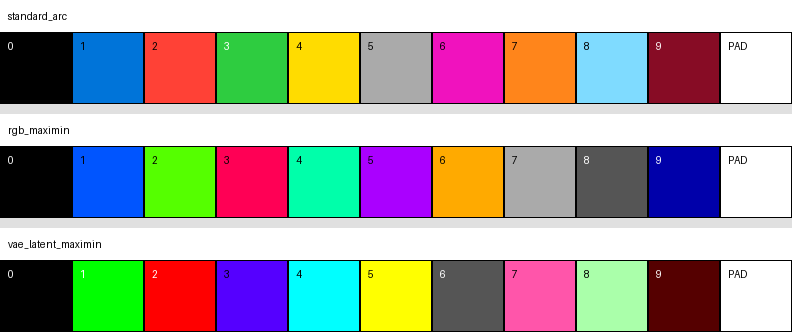

/tmp/ipykernel_8527/1059788972.py:7: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(np.asarray(rgb, dtype=np.uint8), mode='RGB')


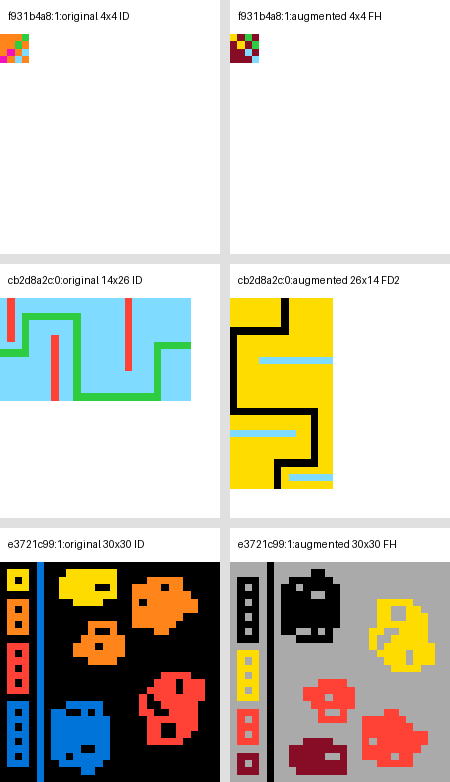

In [ ]:
import html
import math
from PIL import Image, ImageDraw
from IPython.display import HTML, display

def labeled_panel(rgb: np.ndarray, label: str, width: int = 220) -> Image.Image:
    image = Image.fromarray(np.asarray(rgb, dtype=np.uint8), mode='RGB')
    if image.width != width:
        height = round(image.height * width / image.width)
        image = image.resize((width, height), Image.Resampling.NEAREST)
    label_height = 34
    panel = Image.new('RGB', (image.width, image.height + label_height), 'white')
    panel.paste(image, (0, label_height))
    ImageDraw.Draw(panel).text((8, 10), label, fill='black')
    return panel

def join_images(images: list[Image.Image], columns: int, gap: int = 10) -> Image.Image:
    rows = math.ceil(len(images) / columns)
    cell_width = max(image.width for image in images)
    cell_height = max(image.height for image in images)
    canvas = Image.new(
        'RGB',
        (
            columns * cell_width + (columns - 1) * gap,
            rows * cell_height + (rows - 1) * gap,
        ),
        (224, 224, 224),
    )
    for index, image in enumerate(images):
        row, column = divmod(index, columns)
        canvas.paste(image, (column * (cell_width + gap), row * (cell_height + gap)))
    return canvas

def palette_panel(name: str, palette: np.ndarray) -> Image.Image:
    swatch_width = 72
    swatch_height = 72
    title_height = 32
    image = Image.new('RGB', (11 * swatch_width, title_height + swatch_height), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((8, 10), name, fill='black')
    for index, color in enumerate(palette):
        left = index * swatch_width
        draw.rectangle(
            (left, title_height, left + swatch_width - 1, title_height + swatch_height - 1),
            fill=tuple(int(value) for value in color),
            outline='black',
        )
        luminance = float(np.mean(color))
        text_color = 'white' if luminance < 110 else 'black'
        label = 'PAD' if index == PAD_CLASS else str(index)
        draw.text((left + 8, title_height + 8), label, fill=text_color)
    return image

def html_table(rows: list[dict[str, object]], columns: list[str]) -> HTML:
    header = ''.join(f'<th>{html.escape(column)}</th>' for column in columns)
    body = []
    for row in rows:
        cells = ''.join(
            f'<td>{html.escape(str(row.get(column, "")))}</td>' for column in columns
        )
        body.append(f'<tr>{cells}</tr>')
    return HTML(
        '<table style="border-collapse:collapse" border="1" cellpadding="6">'
        f'<thead><tr>{header}</tr></thead><tbody>{"".join(body)}</tbody></table>'
    )

def render_one(labels: np.ndarray, palette: np.ndarray) -> np.ndarray:
    return render_label_canvases(labels, palette)[0]

palette_image = join_images(
    [palette_panel(name, palette) for name, palette in PALETTES.items()],
    columns=1,
)
display(palette_image)

original_indices = [index for index, view in enumerate(VIEWS) if view.variant == 'original']
original_indices.sort(key=lambda index: VIEWS[index].grid.size)
selected_originals = [
    original_indices[0],
    original_indices[len(original_indices) // 2],
    original_indices[-1],
]
real_panels = []
for original_index in selected_originals:
    for view_index in (original_index, original_index + 1):
        view = VIEWS[view_index]
        real_panels.append(
            labeled_panel(
                render_one(EXPECTED_LABELS[view_index], STANDARD_ARC_PALETTE),
                f'{view.view_id} {view.grid.shape[0]}x{view.grid.shape[1]} {view.geometry}',
            )
        )
real_examples_image = join_images(real_panels, columns=2)
display(real_examples_image)

## Clean real-grid round trip and latent separation

Full-canvas accuracy is reported for completeness but is dominated by white
padding on small outputs. The important metrics are:

- **exact grid**: inferred shape and every output cell are correct;
- **shape accuracy**: the PAD boundary yields the correct height and width;
- **grid-cell accuracy**: accuracy only inside the true output rectangle;
- **PAD precision/recall**: separation of output content from the sentinel.

Packed transformer latents are cached on CPU in FP32 so the robustness sweep
introduces no additional quantization variable. The VAE and every decode also
remain FP32.

In [ ]:
def infer_shape(labels: np.ndarray) -> tuple[int, int]:
    positions = np.argwhere(labels != PAD_CLASS)
    if len(positions) == 0:
        return (0, 0)
    return (int(positions[:, 0].max()) + 1, int(positions[:, 1].max()) + 1)

def evaluate_predictions(
    expected: np.ndarray,
    predicted: np.ndarray,
    views: list[ArcGridView],
    indices: np.ndarray,
) -> dict[str, object]:
    matrix = np.zeros((11, 11), dtype=np.int64)
    exact_count = 0
    shape_count = 0
    true_grid_correct = 0
    true_grid_total = 0
    per_grid = []

    for index in indices:
        expected_canvas = expected[index]
        predicted_canvas = predicted[index]
        view = views[index]
        height, width = view.grid.shape
        predicted_shape = infer_shape(predicted_canvas)
        shape_exact = predicted_shape == (height, width)
        grid_correct = int(
            (predicted_canvas[:height, :width] == expected_canvas[:height, :width]).sum()
        )
        grid_total = height * width
        exact = bool(shape_exact and grid_correct == grid_total)

        np.add.at(
            matrix,
            (expected_canvas.ravel(), predicted_canvas.ravel()),
            1,
        )
        exact_count += int(exact)
        shape_count += int(shape_exact)
        true_grid_correct += grid_correct
        true_grid_total += grid_total
        per_grid.append(
            {
                'view_id': view.view_id,
                'exact_grid': exact,
                'shape_exact': shape_exact,
                'expected_shape': [height, width],
                'predicted_shape': list(predicted_shape),
                'grid_cell_accuracy': grid_correct / grid_total,
            }
        )

    correct = int(np.trace(matrix))
    total = int(matrix.sum())
    pad_true_positive = int(matrix[PAD_CLASS, PAD_CLASS])
    predicted_pad = int(matrix[:, PAD_CLASS].sum())
    expected_pad = int(matrix[PAD_CLASS, :].sum())
    count = len(indices)
    return {
        'count': count,
        'exact_grid_count': exact_count,
        'exact_grid_accuracy': exact_count / count,
        'shape_exact_count': shape_count,
        'shape_accuracy': shape_count / count,
        'grid_cell_accuracy': true_grid_correct / true_grid_total,
        'full_canvas_cell_accuracy': correct / total,
        'pad_precision': pad_true_positive / max(1, predicted_pad),
        'pad_recall': pad_true_positive / max(1, expected_pad),
        'confusion_matrix': matrix.tolist(),
        'per_grid': per_grid,
    }

GROUP_INDICES = {
    'all': np.arange(len(VIEWS), dtype=np.int64),
    'original': np.asarray(
        [index for index, view in enumerate(VIEWS) if view.variant == 'original'],
        dtype=np.int64,
    ),
    'augmented': np.asarray(
        [index for index, view in enumerate(VIEWS) if view.variant == 'augmented'],
        dtype=np.int64,
    ),
}

def evaluate_groups(predicted: np.ndarray) -> dict[str, dict[str, object]]:
    return {
        group: evaluate_predictions(EXPECTED_LABELS, predicted, VIEWS, indices)
        for group, indices in GROUP_INDICES.items()
    }

def separation_metrics(prototypes: np.ndarray, spreads: np.ndarray) -> dict[str, float]:
    distances = np.linalg.norm(
        prototypes[:, None, :] - prototypes[None, :, :],
        axis=-1,
    )
    class_distances = distances[:10, :10]
    inter_class = class_distances[~np.eye(10, dtype=bool)]
    pad_distances = distances[:10, PAD_CLASS]
    worst_margin = min(float(inter_class.min()), float(pad_distances.min()))
    mean_spread = float(spreads.mean())
    return {
        'minimum_class_distance': float(inter_class.min()),
        'mean_class_distance': float(inter_class.mean()),
        'minimum_pad_distance': float(pad_distances.min()),
        'mean_within_class_spread': mean_spread,
        'worst_margin_over_spread': worst_margin / max(mean_spread, 1e-12),
    }

clean_summaries = {}
clean_predictions = {}
cached_latents = {}
latent_summaries = {}
class_context_mosaics = balanced_mosaics(
    11, EVALUATION_CONTEXT_MOSAICS, SEED + 200
)

for palette_name, palette in PALETTES.items():
    print('Clean evaluation:', palette_name)
    latent_batches = []
    prediction_batches = []
    for batch_slice in iter_slices(len(VIEWS), BATCH_SIZE):
        rgb = render_label_canvases(EXPECTED_LABELS[batch_slice], palette)
        latent = encode_rgb_batch(rgb)
        reconstruction = decode_transformer_latents(latent)
        prediction_batches.append(classify_cell_batches(reconstruction, palette))
        latent_batches.append(latent.detach().to(device='cpu', dtype=torch.float32))
    predictions = np.concatenate(prediction_batches)
    cached_latents[palette_name] = torch.cat(latent_batches)
    clean_predictions[palette_name] = predictions
    clean_summaries[palette_name] = evaluate_groups(predictions)

    prototypes, spreads = latent_prototypes(class_context_mosaics, palette)
    latent_summaries[palette_name] = separation_metrics(prototypes, spreads)
    torch.cuda.empty_cache()

clean_rows = []
for palette_name in PALETTES:
    latent = latent_summaries[palette_name]
    for group in ('original', 'augmented'):
        summary = clean_summaries[palette_name][group]
        clean_rows.append(
            {
                'palette': palette_name,
                'group': group,
                'exact grids': f'{summary["exact_grid_count"]}/{summary["count"]}',
                'shape accuracy': f'{summary["shape_accuracy"]:.6f}',
                'grid-cell accuracy': f'{summary["grid_cell_accuracy"]:.6f}',
                'PAD precision': f'{summary["pad_precision"]:.6f}',
                'PAD recall': f'{summary["pad_recall"]:.6f}',
                'min class distance': f'{latent["minimum_class_distance"]:.4f}',
                'min PAD distance': f'{latent["minimum_pad_distance"]:.4f}',
            }
        )

display(html_table(clean_rows, list(clean_rows[0])))

Clean evaluation: standard_arc
Clean evaluation: rgb_maximin
Clean evaluation: vae_latent_maximin


palette,group,exact grids,shape accuracy,grid-cell accuracy,PAD precision,PAD recall,min class distance,min PAD distance
standard_arc,original,167/167,1.000000,1.000000,1.000000,1.000000,3.0054,5.9972
standard_arc,augmented,167/167,1.000000,1.000000,1.000000,1.000000,3.0054,5.9972
rgb_maximin,original,167/167,1.000000,1.000000,1.000000,1.000000,3.9333,5.9623
rgb_maximin,augmented,167/167,1.000000,1.000000,1.000000,1.000000,3.9333,5.9623
vae_latent_maximin,original,167/167,1.000000,1.000000,1.000000,1.000000,5.1209,5.4031
vae_latent_maximin,augmented,166/167,1.000000,0.999986,1.000000,1.000000,5.1209,5.4031


## Robustness to normalized transformer-latent noise

Every palette receives the same deterministic noise realization for a given
sigma, repeat, and batch. Results retain each repeat and also provide mean and
standard deviation summaries. Repeat-zero predictions are cached for a later
failure gallery.

In [ ]:
def noise_seed(sigma_index: int, repeat: int, batch_index: int) -> int:
    return SEED + 100_000 + sigma_index * 10_000 + repeat * 1_000 + batch_index

METRIC_NAMES = (
    'exact_grid_accuracy',
    'shape_accuracy',
    'grid_cell_accuracy',
    'full_canvas_cell_accuracy',
    'pad_precision',
    'pad_recall',
)

noise_repeat_results = {name: [] for name in PALETTES}
noise_predictions = {name: {} for name in PALETTES}

for palette_name, palette in PALETTES.items():
    latents_cpu = cached_latents[palette_name]
    print('Noise evaluation:', palette_name)
    for sigma_index, sigma in enumerate(NOISE_SIGMAS[1:], start=1):
        for repeat in range(NOISE_REPEATS):
            prediction_batches = []
            for batch_index, batch_slice in enumerate(iter_slices(len(VIEWS), BATCH_SIZE)):
                latent = latents_cpu[batch_slice].to(
                    device=DEVICE,
                    dtype=torch.float32,
                )
                generator = torch.Generator(device=DEVICE).manual_seed(
                    noise_seed(sigma_index, repeat, batch_index)
                )
                noise = torch.randn(
                    latent.shape,
                    generator=generator,
                    device=DEVICE,
                    dtype=latent.dtype,
                )
                reconstruction = decode_transformer_latents(latent + sigma * noise)
                prediction_batches.append(classify_cell_batches(reconstruction, palette))

            predictions = np.concatenate(prediction_batches)
            if repeat == 0:
                noise_predictions[palette_name][float(sigma)] = predictions
            groups = evaluate_groups(predictions)
            for group, metrics in groups.items():
                noise_repeat_results[palette_name].append(
                    {
                        'sigma': float(sigma),
                        'repeat': repeat,
                        'group': group,
                        'metrics': {
                            'count': metrics['count'],
                            **{metric: metrics[metric] for metric in METRIC_NAMES},
                        },
                    }
                )
        torch.cuda.empty_cache()

def aggregate_noise_results(palette_name: str) -> list[dict[str, object]]:
    rows = []
    for group in ('all', 'original', 'augmented'):
        clean = clean_summaries[palette_name][group]
        rows.append(
            {
                'sigma': 0.0,
                'group': group,
                **{f'{metric}_mean': float(clean[metric]) for metric in METRIC_NAMES},
                **{f'{metric}_std': 0.0 for metric in METRIC_NAMES},
            }
        )
        for sigma in NOISE_SIGMAS[1:]:
            repeats = [
                row['metrics']
                for row in noise_repeat_results[palette_name]
                if row['group'] == group and row['sigma'] == sigma
            ]
            assert len(repeats) == NOISE_REPEATS
            aggregate = {'sigma': float(sigma), 'group': group}
            for metric in METRIC_NAMES:
                values = np.asarray([row[metric] for row in repeats], dtype=np.float64)
                aggregate[f'{metric}_mean'] = float(values.mean())
                aggregate[f'{metric}_std'] = float(values.std(ddof=0))
            rows.append(aggregate)
    return rows

noise_summaries = {
    palette_name: aggregate_noise_results(palette_name)
    for palette_name in PALETTES
}

robustness_rows = []
for palette_name, rows in noise_summaries.items():
    for row in rows:
        if row['group'] != 'all':
            continue
        robustness_rows.append(
            {
                'palette': palette_name,
                'sigma': f'{row["sigma"]:.2f}',
                'exact grid': (
                    f'{row["exact_grid_accuracy_mean"]:.4f} '
                    f'± {row["exact_grid_accuracy_std"]:.4f}'
                ),
                'shape': (
                    f'{row["shape_accuracy_mean"]:.4f} '
                    f'± {row["shape_accuracy_std"]:.4f}'
                ),
                'grid cells': (
                    f'{row["grid_cell_accuracy_mean"]:.4f} '
                    f'± {row["grid_cell_accuracy_std"]:.4f}'
                ),
                'PAD recall': (
                    f'{row["pad_recall_mean"]:.4f} '
                    f'± {row["pad_recall_std"]:.4f}'
                ),
            }
        )

display(html_table(robustness_rows, list(robustness_rows[0])))

Noise evaluation: standard_arc
Noise evaluation: rgb_maximin
Noise evaluation: vae_latent_maximin


palette,sigma,exact grid,shape,grid cells,PAD recall
standard_arc,0.00,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
standard_arc,0.35,0.9910 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
standard_arc,0.50,0.9192 ± 0.0149,1.0000 ± 0.0000,0.9997 ± 0.0000,1.0000 ± 0.0000
standard_arc,0.75,0.3114 ± 0.0127,1.0000 ± 0.0000,0.9926 ± 0.0003,1.0000 ± 0.0000
standard_arc,1.00,0.0010 ± 0.0014,0.1786 ± 0.0075,0.9376 ± 0.0010,0.9819 ± 0.0003
standard_arc,1.50,0.0000 ± 0.0000,0.1257 ± 0.0000,0.6732 ± 0.0003,0.6511 ± 0.0003
standard_arc,2.00,0.0000 ± 0.0000,0.1257 ± 0.0000,0.4727 ± 0.0007,0.4245 ± 0.0021
standard_arc,3.00,0.0000 ± 0.0000,0.1257 ± 0.0000,0.2951 ± 0.0013,0.2364 ± 0.0001
standard_arc,4.00,0.0000 ± 0.0000,0.1257 ± 0.0000,0.2211 ± 0.0009,0.1532 ± 0.0014
rgb_maximin,0.00,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000


## Robustness curves

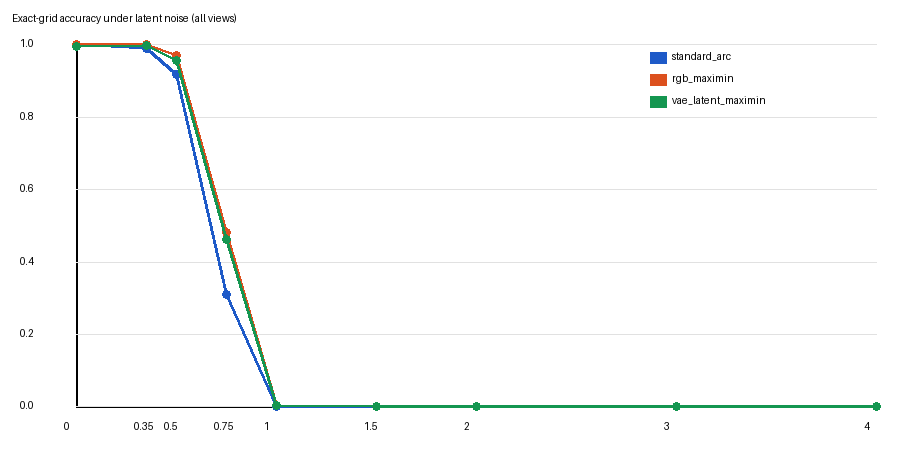

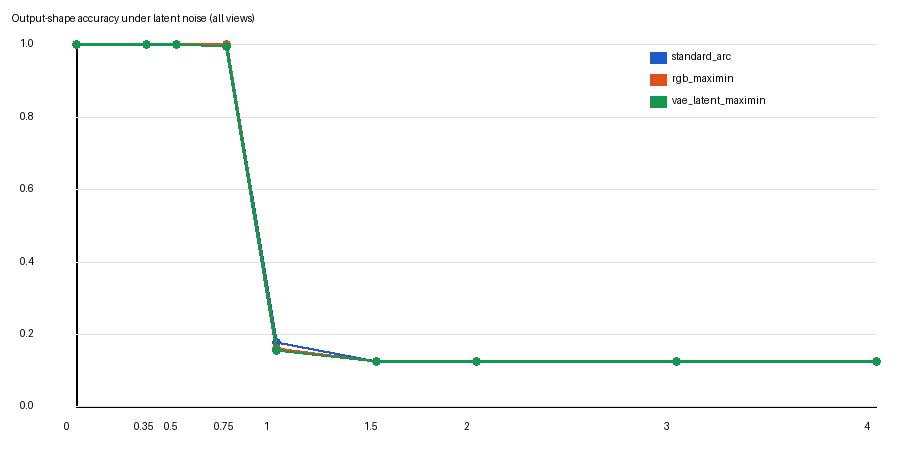

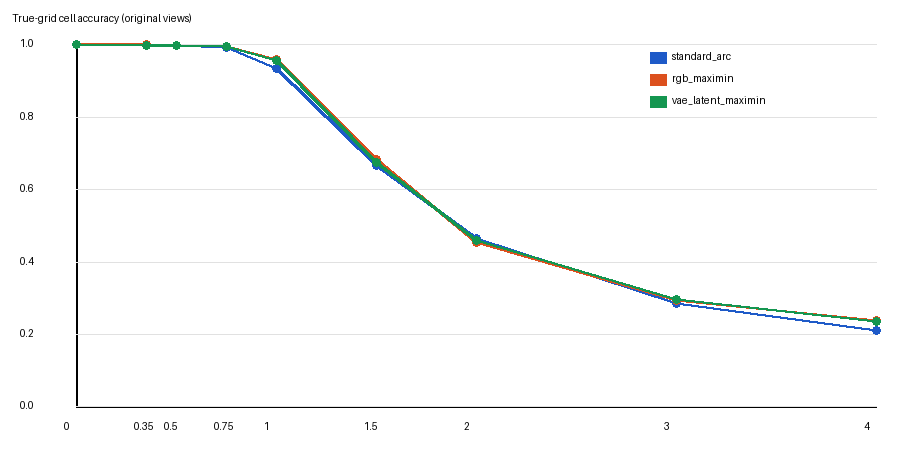

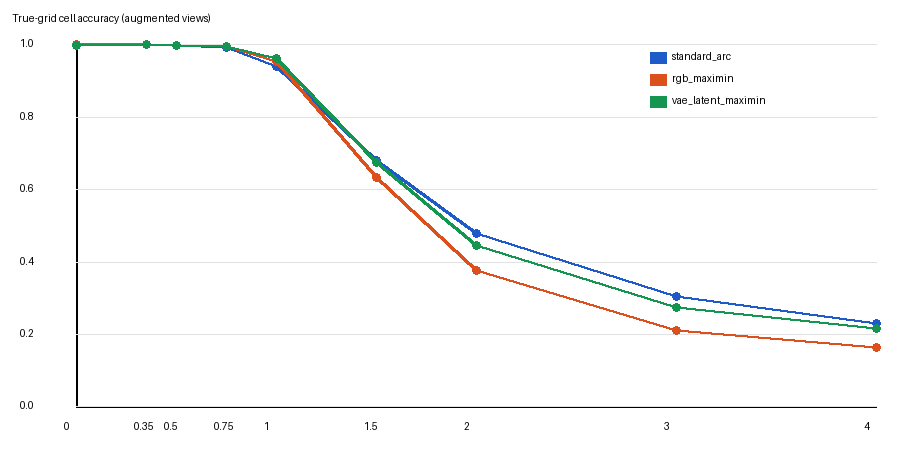

In [ ]:
PLOT_COLORS = {
    'standard_arc': (30, 90, 200),
    'rgb_maximin': (220, 80, 30),
    'vae_latent_maximin': (20, 150, 80),
}

def robustness_plot(metric: str, group: str, title: str) -> Image.Image:
    width = 900
    height = 470
    left, right, top, bottom = 76, 24, 44, 64
    image = Image.new('RGB', (width, height), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((12, 12), title, fill='black')
    draw.line((left, top, left, height - bottom), fill='black', width=2)
    draw.line((left, height - bottom, width - right, height - bottom), fill='black', width=2)

    for tick in np.linspace(0.0, 1.0, 6):
        y = height - bottom - int(tick * (height - top - bottom))
        draw.line((left, y, width - right, y), fill=(225, 225, 225))
        draw.text((20, y - 7), f'{tick:.1f}', fill='black')

    max_sigma = max(NOISE_SIGMAS)
    for palette_name, rows in noise_summaries.items():
        selected = [row for row in rows if row['group'] == group]
        selected.sort(key=lambda row: row['sigma'])
        points = []
        for row in selected:
            x = left + int(row['sigma'] / max_sigma * (width - left - right))
            value = row[f'{metric}_mean']
            y = height - bottom - int(value * (height - top - bottom))
            points.append((x, y))
        draw.line(points, fill=PLOT_COLORS[palette_name], width=3)
        for point in points:
            draw.ellipse(
                (point[0] - 4, point[1] - 4, point[0] + 4, point[1] + 4),
                fill=PLOT_COLORS[palette_name],
            )

    for sigma in NOISE_SIGMAS:
        x = left + int(sigma / max_sigma * (width - left - right))
        draw.text((x - 12, height - bottom + 14), f'{sigma:g}', fill='black')

    legend_y = 52
    for palette_name, color in PLOT_COLORS.items():
        draw.rectangle((width - 250, legend_y, width - 234, legend_y + 11), fill=color)
        draw.text((width - 228, legend_y - 2), palette_name, fill='black')
        legend_y += 22
    return image

robustness_images = {
    'exact-grid-all': robustness_plot(
        'exact_grid_accuracy', 'all', 'Exact-grid accuracy under latent noise (all views)'
    ),
    'shape-all': robustness_plot(
        'shape_accuracy', 'all', 'Output-shape accuracy under latent noise (all views)'
    ),
    'grid-cell-original': robustness_plot(
        'grid_cell_accuracy', 'original', 'True-grid cell accuracy (original views)'
    ),
    'grid-cell-augmented': robustness_plot(
        'grid_cell_accuracy', 'augmented', 'True-grid cell accuracy (augmented views)'
    ),
}
for image in robustness_images.values():
    display(image)

## Representative failure gallery

The gallery automatically chooses the first sigma where the standard palette's
mean exact-grid accuracy falls below 95%. If that never happens, it uses the
largest sigma. Actual VAE reconstructions are regenerated with the exact
repeat-zero batch seeds used above.

/tmp/ipykernel_8527/1059788972.py:7: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(np.asarray(rgb, dtype=np.uint8), mode='RGB')


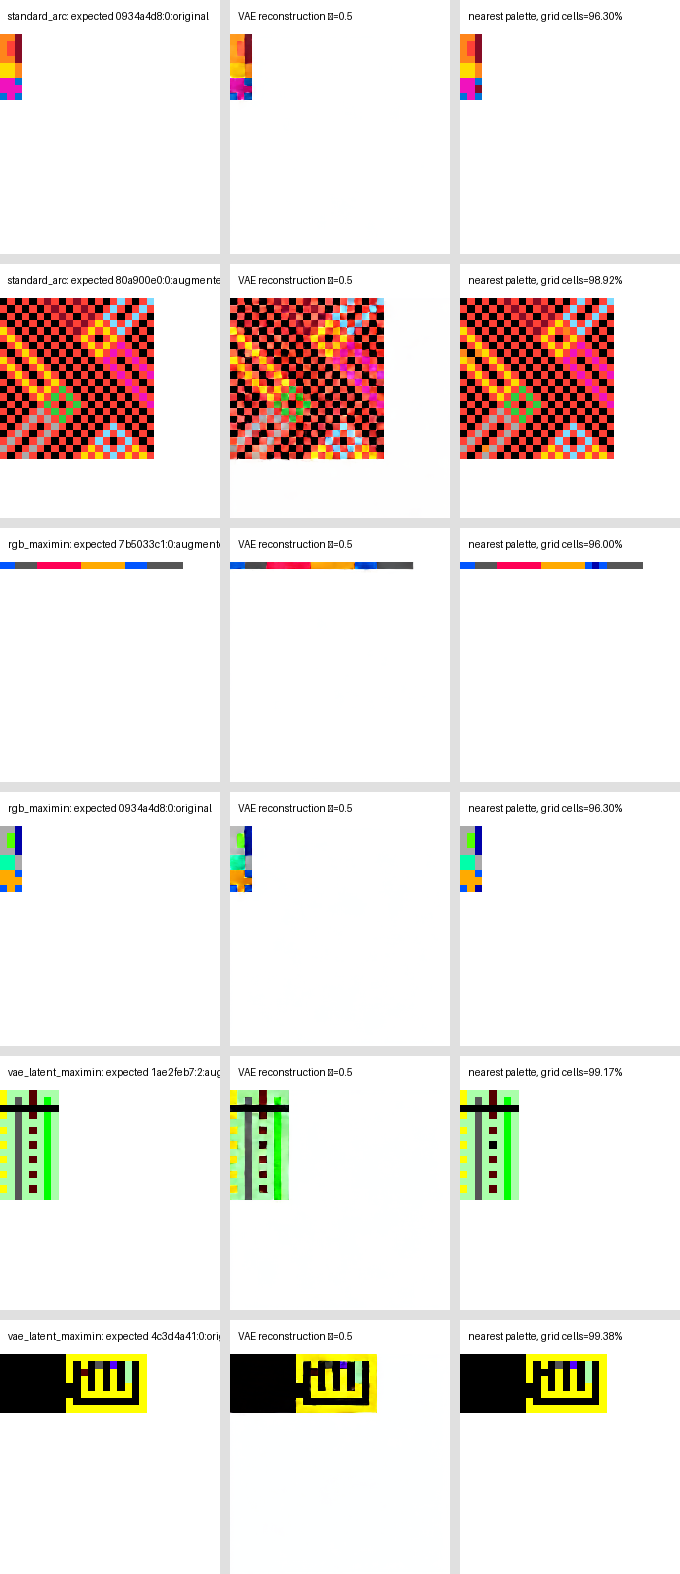

{'comparison_sigma': 0.5,
 'views': {'standard_arc': ['0934a4d8:0:original', '80a900e0:0:augmented'],
  'rgb_maximin': ['7b5033c1:0:augmented', '0934a4d8:0:original'],
  'vae_latent_maximin': ['1ae2feb7:2:augmented', '4c3d4a41:0:original']}}

In [ ]:
standard_all_rows = sorted(
    [row for row in noise_summaries['standard_arc'] if row['group'] == 'all'],
    key=lambda row: row['sigma'],
)
comparison_sigma = next(
    (
        row['sigma']
        for row in standard_all_rows
        if row['sigma'] > 0 and row['exact_grid_accuracy_mean'] < 0.95
    ),
    max(NOISE_SIGMAS),
)
comparison_sigma_index = NOISE_SIGMAS.index(comparison_sigma)

def grid_cell_accuracy_for_index(predicted: np.ndarray, index: int) -> float:
    height, width = VIEWS[index].grid.shape
    return float(
        np.mean(
            predicted[index, :height, :width]
            == EXPECTED_LABELS[index, :height, :width]
        )
    )

def reconstruct_selected(
    palette_name: str,
    sigma: float,
    indices: list[int],
) -> dict[int, np.ndarray]:
    palette_latents = cached_latents[palette_name]
    selected = set(indices)
    reconstructions = {}
    for batch_index, batch_slice in enumerate(iter_slices(len(VIEWS), BATCH_SIZE)):
        batch_indices = [
            index
            for index in selected
            if batch_slice.start <= index < batch_slice.stop
        ]
        if not batch_indices:
            continue
        latent = palette_latents[batch_slice].to(device=DEVICE, dtype=torch.float32)
        generator = torch.Generator(device=DEVICE).manual_seed(
            noise_seed(comparison_sigma_index, 0, batch_index)
        )
        noise = torch.randn(
            latent.shape,
            generator=generator,
            device=DEVICE,
            dtype=latent.dtype,
        )
        rgb = decode_transformer_latents(latent + sigma * noise)
        for index in batch_indices:
            reconstructions[index] = rgb[index - batch_slice.start]
    assert set(reconstructions) == selected
    return reconstructions

gallery_panels = []
gallery_manifest = {}
for palette_name, palette in PALETTES.items():
    predicted = noise_predictions[palette_name][float(comparison_sigma)]
    ranked = sorted(
        range(len(VIEWS)),
        key=lambda index: (
            grid_cell_accuracy_for_index(predicted, index),
            VIEWS[index].view_id,
        ),
    )
    selected = ranked[:2]
    reconstructions = reconstruct_selected(palette_name, comparison_sigma, selected)
    gallery_manifest[palette_name] = [VIEWS[index].view_id for index in selected]
    for index in selected:
        accuracy = grid_cell_accuracy_for_index(predicted, index)
        gallery_panels.extend(
            [
                labeled_panel(
                    render_one(EXPECTED_LABELS[index], palette),
                    f'{palette_name}: expected {VIEWS[index].view_id}',
                ),
                labeled_panel(
                    reconstructions[index],
                    f'VAE reconstruction σ={comparison_sigma:g}',
                ),
                labeled_panel(
                    render_one(predicted[index], palette),
                    f'nearest palette, grid cells={accuracy:.2%}',
                ),
            ]
        )

failure_gallery_image = join_images(gallery_panels, columns=3)
display(failure_gallery_image)
{'comparison_sigma': comparison_sigma, 'views': gallery_manifest}

## Decision rule

A candidate is promoted only to a later FLUX training A/B test. It must not
materially harm clean exact-grid, shape, or true-grid cell accuracy, and it
must improve average non-zero-noise robustness over the standard ARC palette.
This notebook does not directly change the production palette.

In [ ]:
CLEAN_TOLERANCE = 1e-4

def mean_noise_metric(palette_name: str, metric: str, group: str = 'all') -> float:
    values = [
        row[f'{metric}_mean']
        for row in noise_summaries[palette_name]
        if row['group'] == group and row['sigma'] > 0
    ]
    return float(np.mean(values))

baseline_name = 'standard_arc'
decisions = {}
decision_rows = []
for candidate_name in ('rgb_maximin', 'vae_latent_maximin'):
    clean_baseline = clean_summaries[baseline_name]['all']
    clean_candidate = clean_summaries[candidate_name]['all']
    clean_not_worse = all(
        clean_candidate[metric] + CLEAN_TOLERANCE >= clean_baseline[metric]
        for metric in (
            'exact_grid_accuracy',
            'shape_accuracy',
            'grid_cell_accuracy',
            'pad_recall',
        )
    )
    exact_score = mean_noise_metric(candidate_name, 'exact_grid_accuracy')
    baseline_exact_score = mean_noise_metric(baseline_name, 'exact_grid_accuracy')
    cell_score = mean_noise_metric(candidate_name, 'grid_cell_accuracy')
    baseline_cell_score = mean_noise_metric(baseline_name, 'grid_cell_accuracy')
    robustness_better = (
        exact_score > baseline_exact_score and cell_score > baseline_cell_score
    )
    qualifies = bool(clean_not_worse and robustness_better)
    decisions[candidate_name] = {
        'clean_not_worse': bool(clean_not_worse),
        'mean_nonzero_noise_exact_grid_accuracy': exact_score,
        'baseline_mean_nonzero_noise_exact_grid_accuracy': baseline_exact_score,
        'mean_nonzero_noise_grid_cell_accuracy': cell_score,
        'baseline_mean_nonzero_noise_grid_cell_accuracy': baseline_cell_score,
        'robustness_better': bool(robustness_better),
        'qualifies_for_flux_training_ab_test': qualifies,
    }
    decision_rows.append(
        {
            'candidate': candidate_name,
            'clean not worse': clean_not_worse,
            'noise exact': f'{exact_score:.6f} vs {baseline_exact_score:.6f}',
            'noise grid cells': f'{cell_score:.6f} vs {baseline_cell_score:.6f}',
            'qualifies for FLUX A/B': qualifies,
        }
    )

display(html_table(decision_rows, list(decision_rows[0])))
decisions

candidate,clean not worse,noise exact,noise grid cells,qualifies for FLUX A/B
rgb_maximin,True,0.306761 vs 0.277819,0.685119 vs 0.698998,False
vae_latent_maximin,False,0.302894 vs 0.277819,0.699678 vs 0.698998,False


{'rgb_maximin': {'clean_not_worse': True,
  'mean_nonzero_noise_exact_grid_accuracy': 0.30676147704590817,
  'baseline_mean_nonzero_noise_exact_grid_accuracy': 0.2778193612774451,
  'mean_nonzero_noise_grid_cell_accuracy': 0.6851191749881121,
  'baseline_mean_nonzero_noise_grid_cell_accuracy': 0.6989984545886828,
  'robustness_better': False,
  'qualifies_for_flux_training_ab_test': False},
 'vae_latent_maximin': {'clean_not_worse': False,
  'mean_nonzero_noise_exact_grid_accuracy': 0.30289421157684626,
  'baseline_mean_nonzero_noise_exact_grid_accuracy': 0.2778193612774451,
  'mean_nonzero_noise_grid_cell_accuracy': 0.6996781383737518,
  'baseline_mean_nonzero_noise_grid_cell_accuracy': 0.6989984545886828,
  'robustness_better': True,
  'qualifies_for_flux_training_ab_test': False}}

## Save the reproducibility report and visual artifacts

In [ ]:
from datetime import datetime, timezone

def compact_group_summary(summary: dict[str, object]) -> dict[str, object]:
    return {key: value for key, value in summary.items() if key != 'per_grid'}

palette_image.save(OUTPUT_DIR / 'palettes.png')
real_examples_image.save(OUTPUT_DIR / 'real-arc-examples.png')
failure_gallery_image.save(OUTPUT_DIR / 'failure-gallery.png')
for name, image in robustness_images.items():
    image.save(OUTPUT_DIR / f'robustness-{name}.png')

report = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'protocol': {
        'public_evaluation_role': 'development_set',
        'final_evaluation_role': 'hidden_kaggle_private_set',
        'nvarc_public_evaluation_contamination_acknowledged': True,
    },
    'runtime': runtime,
    'configuration': {
        'seed': SEED,
        'grid_size': GRID_SIZE,
        'cell_size': CELL_SIZE,
        'image_size': IMAGE_SIZE,
        'pad_class': PAD_CLASS,
        'pad_rgb': list(PAD_RGB),
        'candidate_levels': list(CANDIDATE_LEVELS),
        'search_context_mosaics': SEARCH_CONTEXT_MOSAICS,
        'evaluation_context_mosaics': EVALUATION_CONTEXT_MOSAICS,
        'noise_sigmas': list(NOISE_SIGMAS),
        'noise_repeats': NOISE_REPEATS,
        'batch_size': BATCH_SIZE,
        'geometries': list(GEOMETRIES),
        'posterior_statistic': 'mode',
        'cached_latent_dtype': 'float32_cpu',
        'vae_compute_dtype': 'float32',
        'transformer_latent_shape': [128, 30, 30],
    },
    'dataset': dataset_stats,
    'views': view_stats,
    'palettes': {name: palette.tolist() for name, palette in PALETTES.items()},
    'selection': {
        'rgb_candidate_indices': list(rgb_selected_indices),
        'vae_candidate_indices': list(vae_selected_indices),
    },
    'clean_roundtrip': {
        palette_name: {
            group: compact_group_summary(summary)
            for group, summary in groups.items()
        }
        for palette_name, groups in clean_summaries.items()
    },
    'clean_per_grid': {
        palette_name: groups['all']['per_grid']
        for palette_name, groups in clean_summaries.items()
    },
    'latent_separation': latent_summaries,
    'latent_noise_summary': noise_summaries,
    'latent_noise_repeats': noise_repeat_results,
    'failure_gallery': {
        'sigma': comparison_sigma,
        'views': gallery_manifest,
    },
    'decision': decisions,
}

report_path = OUTPUT_DIR / 'metrics.json'
report_path.write_text(json.dumps(report, indent=2), encoding='utf-8')

{
    'report': str(report_path),
    'artifacts': sorted(path.name for path in OUTPUT_DIR.glob('*.png')),
    'decision': decisions,
}

{'report': '/content/drive/MyDrive/diffusion-arc/outputs/vae-palette-real-evaluation/metrics.json',
 'artifacts': ['failure-gallery.png',
  'palettes.png',
  'real-arc-examples.png',
  'robustness-exact-grid-all.png',
  'robustness-grid-cell-augmented.png',
  'robustness-grid-cell-original.png',
  'robustness-shape-all.png'],
 'decision': {'rgb_maximin': {'clean_not_worse': True,
   'mean_nonzero_noise_exact_grid_accuracy': 0.30676147704590817,
   'baseline_mean_nonzero_noise_exact_grid_accuracy': 0.2778193612774451,
   'mean_nonzero_noise_grid_cell_accuracy': 0.6851191749881121,
   'baseline_mean_nonzero_noise_grid_cell_accuracy': 0.6989984545886828,
   'robustness_better': False,
   'qualifies_for_flux_training_ab_test': False},
  'vae_latent_maximin': {'clean_not_worse': False,
   'mean_nonzero_noise_exact_grid_accuracy': 0.30289421157684626,
   'baseline_mean_nonzero_noise_exact_grid_accuracy': 0.2778193612774451,
   'mean_nonzero_noise_grid_cell_accuracy': 0.6996781383737518,
   '

## Interpretation and next step

Use the exact-grid and shape curves first; full-canvas cell accuracy can look
deceptively strong because most cells are PAD. The original-view curves reflect
direct public-development rendering, while augmented-view curves stress the
distribution used during training.

A qualifying candidate should next be tested with a small, fixed FLUX training
A/B run. Do not reinterpret these public-development results as an independent
final score; the hidden Kaggle private set remains the only final evaluation.

In [ ]:
import json

report_path = OUTPUT_DIR / "metrics.json"
expected_files = {
    "metrics.json",
    "palettes.png",
    "real-arc-examples.png",
    "failure-gallery.png",
    "robustness-exact-grid-all.png",
    "robustness-shape-all.png",
    "robustness-grid-cell-original.png",
    "robustness-grid-cell-augmented.png",
}

existing_files = {path.name for path in OUTPUT_DIR.iterdir()}
assert report_path.is_file()
assert not (expected_files - existing_files), expected_files - existing_files

report = json.loads(report_path.read_text())

{
    "dataset": {
        "tasks": report["dataset"]["task_count"],
        "outputs": report["dataset"]["output_count"],
        "sha256": report["dataset"]["sha256"],
    },
    "decision": report["decision"],
    "files": {
        path.name: round(path.stat().st_size / 1024**2, 3)
        for path in sorted(OUTPUT_DIR.iterdir())
    },
    "max_cuda_allocated_GiB": round(
        torch.cuda.max_memory_allocated() / 1024**3, 2
    ),
    "max_cuda_reserved_GiB": round(
        torch.cuda.max_memory_reserved() / 1024**3, 2
    ),
}

{'dataset': {'tasks': 120,
  'outputs': 167,
  'sha256': '1acd8f5e3559183e1b06d332a5c1d98f0941796b63821bf860c93466ebdfdbd9'},
 'decision': {'rgb_maximin': {'clean_not_worse': True,
   'mean_nonzero_noise_exact_grid_accuracy': 0.30676147704590817,
   'baseline_mean_nonzero_noise_exact_grid_accuracy': 0.2778193612774451,
   'mean_nonzero_noise_grid_cell_accuracy': 0.6851191749881121,
   'baseline_mean_nonzero_noise_grid_cell_accuracy': 0.6989984545886828,
   'robustness_better': False,
   'qualifies_for_flux_training_ab_test': False},
  'vae_latent_maximin': {'clean_not_worse': False,
   'mean_nonzero_noise_exact_grid_accuracy': 0.30289421157684626,
   'baseline_mean_nonzero_noise_exact_grid_accuracy': 0.2778193612774451,
   'mean_nonzero_noise_grid_cell_accuracy': 0.6996781383737518,
   'baseline_mean_nonzero_noise_grid_cell_accuracy': 0.6989984545886828,
   'robustness_better': True,
   'qualifies_for_flux_training_ab_test': False}},
 'files': {'failure-gallery.png': 0.132,
  'metrics.